In [1]:
# ---------------------------------------------------------------------------
# 1. Import dan direktori proyek
# ---------------------------------------------------------------------------
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict
from contextlib import redirect_stdout
from importlib.metadata import version, PackageNotFoundError
import hashlib
import json
import platform
import shutil
import sys
import traceback

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.impute import KNNImputer
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, RobustScaler
from torch.utils.data import DataLoader

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "multimodal_mil_model.py").is_file()
    and (p / "app_data_filtered.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from multimodal_mil_model import (
    ModelConfig, MultimodalMILModel, OptimizerConfig,
    build_optimizer, collate_bags, count_parameters, labels_to_class,
)
from image_preprocessing import (
    ImagePreprocessConfig, ImageTransform, PatientBagDataset,
    compute_train_stats, save_stats,
)
from training import (
    CLASS_NAMES, binary_metrics, compute_metrics,
    fit, plot_history, run_epoch, set_seed,
)

from experiment_runner import (
    AUROC_DEFINITION, make_scenarios, fingerprint, run_scenario_search,
    evaluate_search_winner,
)

from experiment_evaluation import print_test_report


In [2]:
# ---------------------------------------------------------------------------
# 2. Konfigurasi eksperimen
# ---------------------------------------------------------------------------
SEED = 1
SPLIT_SEED = 1
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_DEVELOPMENT = 0.20

EPOCHS = 100
BATCH_SIZE = 16
NUM_WORKERS = 0
USE_AMP = True
MONITOR = "val_f1"  # macro-F1 tiga kelas dari keputusan hierarkis
EARLY_STOPPING_PATIENCE = 25
EARLY_STOPPING_RULE = "best_monitor"
EARLY_STOPPING_MIN_DELTA = 0.0
THRESHOLD = 0.5
TEST_BOOTSTRAP_RESAMPLES = 1000  # Bootstrap pasien, stratifikasi tiga kelas; CI 95%.

ID_COL, TARGET_COL = "US_Number", "Label"
EXCLUDED_FEATURES = []  # Semua 53 fitur klinis referensi, termasuk Length_of_Stay.
MAX_MISSING_KNN = 0.50
N_NEIGHBORS = 5

TABULAR_PATH = ROOT / "app_data_filtered.csv"
MANIFEST_PATH = ROOT / "image_manifest_filtered.csv"
IMAGE_ROOT = ROOT / "US_Pictures_clean"
EXPERIMENT_DIR = ROOT / "experiments" / "Experiment 1"
NOTEBOOK_PATH = EXPERIMENT_DIR / "Experiment 1 (MIL-Attention Dual Fusion MLP Hierarchical).ipynb"
RESUME_SEARCH_DIR = None  # Search 53 fitur baru; run lama 52 fitur tidak dapat dilanjutkan.
RETRY_FAILED = False     # True: ulangi trial gagal/interupsi; hasil lama diarsipkan.
RUN_ID = "search_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f") + f"_seed{SEED}"
RUN_DIR = Path(RESUME_SEARCH_DIR).resolve() if RESUME_SEARCH_DIR else EXPERIMENT_DIR / "runs" / RUN_ID
RUN_ID = RUN_DIR.name

# Paper referensi: 80% training dan 20% testing pada tingkat pasien (halaman 4).
# Validasi internal tidak dijelaskan; di sini 20% development dipakai sebagai val.
# Proporsi efektif: sekitar 64% train, 16% val, 20% test; stratifikasi tiga kelas.
# Seed split tetap terpisah dari seed training agar pembanding memakai pasien sama.
# Length_of_Stay dipertahankan untuk baseline fitur referensi sesuai rancangan Experiment 1.
# Encoding/imputasi E0 dipertahankan; ini baseline, bukan reproduksi persis paper.

model_options = dict(
    backbone="resnet18",
    pretrained=True,
    freeze_backbone=True,
    backbone_trainable_stage=None,
    aggregation="attention",
    attention_fusion="dual",
    attention_gated=True,
    head="dual_head",
    tabular_encoder="mlp",
    tabular_embed_dim=64,
    mlp_hidden_dims=(128,),
    image_embed_dim=None,
    fusion_hidden_dims=(256, 64),
    use_dropout=True,
    dropout_rate=0.4,
    complication_loss_weight=1.0,
    tabnet_sparsity_weight=0.0,
)

opt_config = OptimizerConfig(
    name="adam", lr=1e-4, weight_decay=1e-3, backbone_lr_multiplier=0.1,
)
img_cfg = ImagePreprocessConfig()

# 3 kondisi backbone x 3 optimizer x 4 profil = 36 skenario.
# P1: lr=1e-4, dropout=0.4, wd=1e-3; P2: 1e-3, 0.2, 1e-4.
# P3: lr=1e-5, dropout=0.7, wd=1e-3; P4: 1e-4, 0.7, 1e-4.
SCENARIOS = make_scenarios()
SEARCH_SETTINGS = dict(
    seed=SEED, epochs=EPOCHS, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    use_amp=USE_AMP, monitor=MONITOR, patience=EARLY_STOPPING_PATIENCE,
    min_delta=EARLY_STOPPING_MIN_DELTA, threshold=THRESHOLD,
    early_stopping_rule=EARLY_STOPPING_RULE, test_bootstrap_resamples=TEST_BOOTSTRAP_RESAMPLES,
    device="cuda" if torch.cuda.is_available() else "cpu",
    save_plots=True, verbose=True,
)
# Checkpoint dan early stopping: best validation macro-F1, patience 25.
# F1 sama: checkpoint dengan val_loss lebih rendah; tidak mereset patience.
# Maksimum training tetap 100 epoch; berhenti setelah 25 epoch tanpa peningkatan best F1.
# Test hanya dijalankan untuk pemenang validasi setelah seluruh antrean selesai.


In [3]:
# ---------------------------------------------------------------------------
# 3. Dokumentasi search dan snapshot input
# ---------------------------------------------------------------------------
from experiment_runner import file_sha256, write_json

source_hashes = {
    name: file_sha256(ROOT / name)
    for name in ["multimodal_mil_model.py", "training.py", "image_preprocessing.py", "experiment_runner.py", "experiment_evaluation.py"]
}
input_hashes = {path.name: file_sha256(path) for path in [TABULAR_PATH, MANIFEST_PATH]}
notebook_on_disk = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
logic = [
    "".join(cell["source"]) for i, cell in enumerate(notebook_on_disk["cells"])
    if i not in (1, len(notebook_on_disk["cells"]) - 1)
]
search_definition = {
    "seed": SEED, "split_seed": SPLIT_SEED, "test_size": TEST_SIZE,
    "val_size_within_development": VAL_SIZE_WITHIN_DEVELOPMENT,
    "excluded_features": EXCLUDED_FEATURES,
    "preprocessing": {
        "max_missing_knn": MAX_MISSING_KNN, "n_neighbors": N_NEIGHBORS,
        "image": asdict(img_cfg),
    },
    "base_model_options": model_options, "base_optimizer": asdict(opt_config),
    "training": SEARCH_SETTINGS, "scenarios": SCENARIOS,
    "input_sha256": input_hashes, "source_sha256": source_hashes,
    "notebook_logic_sha256": fingerprint(logic),
}
signature = fingerprint(search_definition)
if RESUME_SEARCH_DIR:
    assert RUN_DIR.is_dir(), "Folder search lama tidak ditemukan."
    previous = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
    assert previous["search_fingerprint"] == signature, "Konfigurasi/kode berubah; gunakan search baru."
else:
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR / "inputs").mkdir()
    (RUN_DIR / "source").mkdir()
    for path in [TABULAR_PATH, MANIFEST_PATH]:
        shutil.copy2(path, RUN_DIR / "inputs" / path.name)
    for name in source_hashes:
        shutil.copy2(ROOT / name, RUN_DIR / "source" / name)
    shutil.copy2(NOTEBOOK_PATH, RUN_DIR / "source" / NOTEBOOK_PATH.name)

packages = {}
for name in ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "scipy", "Pillow", "joblib"]:
    try:
        packages[name] = version(name)
    except PackageNotFoundError:
        packages[name] = None
if not (RUN_DIR / "environment.json").exists():
    write_json(RUN_DIR / "environment.json", {
        "python": platform.python_version(), "platform": platform.platform(),
        "packages": packages, "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    })

config = {
    "experiment": "Experiment 1", "run_id": RUN_ID, "search_fingerprint": signature,
    **search_definition,
    "execution": "serial", "scenario_count": len(SCENARIOS),
    "auroc_definition": AUROC_DEFINITION, "monitor": MONITOR,
    "primary_metric": "macro_f1_hierarchical_three_classes",
    "prediction_time": "baseline fitur referensi; waktu ketersediaan fitur belum dibatasi",
    "evaluation": {"threshold": THRESHOLD, "test_policy": "validation_winner_only_manual_final_cell"},
}
write_json(RUN_DIR / "config.json", config)
pd.DataFrame(SCENARIOS).to_csv(RUN_DIR / "scenarios.csv", index=False)
print(f"Search: {RUN_ID}\nOutput: {RUN_DIR}\nMonitor: {MONITOR} ({AUROC_DEFINITION})")


Search: search_20261018_044822_847109_seed1
Output: d:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\experiments\Experiment 1\runs\search_20261018_044822_847109_seed1
Monitor: val_f1 (macro_one_vs_rest_three_classes)


In [4]:
# ---------------------------------------------------------------------------
# 4. Data pasien dan label
# ---------------------------------------------------------------------------
tabular_data = pd.read_csv(RUN_DIR / "inputs" / TABULAR_PATH.name)
manifest = pd.read_csv(RUN_DIR / "inputs" / MANIFEST_PATH.name)

required = {ID_COL, "Diagnosis", "Severity"}
assert required.issubset(tabular_data.columns)
assert tabular_data[ID_COL].notna().all()
assert tabular_data[ID_COL].is_unique
assert (tabular_data[ID_COL] % 1 == 0).all()
tabular_data[ID_COL] = tabular_data[ID_COL].astype(int)

invalid_diagnosis = ~tabular_data["Diagnosis"].isin(["no appendicitis", "appendicitis"])
invalid_severity = (
    tabular_data["Diagnosis"].eq("appendicitis")
    & ~tabular_data["Severity"].isin(["uncomplicated", "complicated"])
)
inconsistent_label = (
    tabular_data["Diagnosis"].eq("no appendicitis")
    & tabular_data["Severity"].eq("complicated")
)
excluded = invalid_diagnosis | invalid_severity | inconsistent_label
exclusion_log = tabular_data.loc[excluded, [ID_COL, "Diagnosis", "Severity"]].copy()
exclusion_log["reason"] = [
    "; ".join(
        reason for condition, reason in [
            (invalid_diagnosis.loc[i], "diagnosis_missing_or_unknown"),
            (invalid_severity.loc[i], "appendicitis_severity_missing_or_unknown"),
            (inconsistent_label.loc[i], "inconsistent_diagnosis_severity"),
        ] if condition
    )
    for i in exclusion_log.index
]
exclusion_log.to_csv(RUN_DIR / "exclusion_log.csv", index=False)

cohort = tabular_data.loc[~excluded].copy().sort_values(ID_COL).reset_index(drop=True)
cohort[TARGET_COL] = np.select(
    [cohort["Diagnosis"].eq("no appendicitis"), cohort["Severity"].eq("uncomplicated")],
    ["no appendicitis", "uncomplicated_appendicitis"],
    default="complicated_appendicitis",
)
assert cohort[ID_COL].isin(manifest[ID_COL]).all()
cohort.to_csv(RUN_DIR / "cohort.csv", index=False)
print(f"Pasien awal: {len(tabular_data)} | dikeluarkan: {excluded.sum()} | cohort: {len(cohort)}")
print(cohort[TARGET_COL].value_counts().to_string())


Pasien awal: 579 | dikeluarkan: 1 | cohort: 578
Label
uncomplicated_appendicitis    286
no appendicitis               196
complicated_appendicitis       96


In [5]:
# ---------------------------------------------------------------------------
# 5. Split pasien 80:20 dan validasi internal
# ---------------------------------------------------------------------------
development, test_data = train_test_split(
    cohort, test_size=TEST_SIZE, random_state=SPLIT_SEED, stratify=cohort[TARGET_COL],
)
train_data, val_data = train_test_split(
    development, test_size=VAL_SIZE_WITHIN_DEVELOPMENT,
    random_state=SPLIT_SEED, stratify=development[TARGET_COL],
)
splits = {"train": train_data, "val": val_data, "test": test_data}
split_manifest = pd.concat([
    pd.DataFrame({
        "patient_id": frame[ID_COL].to_numpy(),
        "label": frame[TARGET_COL].to_numpy(),
        "split": name, "order": np.arange(len(frame)),
    })
    for name, frame in splits.items()
], ignore_index=True)

split_protocol = {
    "cohort_sha256": file_sha256(RUN_DIR / "cohort.csv"),
    "manifest_sha256": input_hashes[MANIFEST_PATH.name],
    "split_seed": SPLIT_SEED, "test_size": TEST_SIZE,
    "val_size_within_development": VAL_SIZE_WITHIN_DEVELOPMENT,
    "stratify": TARGET_COL, "unit": "patient",
}
split_dir = EXPERIMENT_DIR / "data"
split_dir.mkdir(parents=True, exist_ok=True)
split_path, protocol_path = split_dir / "split_manifest.csv", split_dir / "split_protocol.json"
if split_path.exists() or protocol_path.exists():
    assert split_path.exists() and protocol_path.exists(), "Artefak split tidak lengkap."
    assert json.loads(protocol_path.read_text()) == split_protocol, "Protokol/cohort berbeda dari split terkunci."
    pd.testing.assert_frame_equal(pd.read_csv(split_path), split_manifest, check_dtype=False)
else:
    split_manifest.to_csv(split_path, index=False)
    write_json(protocol_path, split_protocol)

shutil.copy2(split_path, RUN_DIR / "split_manifest.csv")
shutil.copy2(protocol_path, RUN_DIR / "split_protocol.json")
ids = {name: set(frame[ID_COL]) for name, frame in splits.items()}
assert not (ids["train"] & ids["val"] or ids["train"] & ids["test"] or ids["val"] & ids["test"])
assert set.union(*ids.values()) == set(cohort[ID_COL])
assert split_manifest.patient_id.is_unique

# Citra dibaca langsung dari folder clean; tidak ada penyalinan/penghapusan split citra.
split_manifests = {
    name: manifest[manifest[ID_COL].isin(patient_ids)].copy()
    for name, patient_ids in ids.items()
}
for name, frame in split_manifests.items():
    assert set(frame[ID_COL]) == ids[name]
    assert not frame["path"].duplicated().any()
    assert all(
        (IMAGE_ROOT / path).resolve().is_relative_to(IMAGE_ROOT.resolve())
        and (IMAGE_ROOT / path).is_file()
        for path in frame["path"]
    )
    frame.to_csv(RUN_DIR / f"{name}_image_manifest.csv", index=False)

# Duplikat dalam satu pasien dicatat; duplikat antar-split harus diinvestigasi.
image_integrity = pd.concat([
    frame[[ID_COL, "path"]].assign(split=name)
    for name, frame in split_manifests.items()
], ignore_index=True)
image_integrity["sha256"] = [file_sha256(IMAGE_ROOT / p) for p in image_integrity["path"]]
image_integrity.to_csv(RUN_DIR / "image_integrity.csv", index=False)
assert image_integrity.groupby("sha256")["split"].nunique().max() == 1, "Duplikat citra antar-split."

summary = pd.DataFrame({
    "patients": {name: len(frame) for name, frame in splits.items()},
    "images": {name: len(frame) for name, frame in split_manifests.items()},
})
summary["fraction"] = summary["patients"] / len(cohort)
summary.to_csv(RUN_DIR / "split_summary.csv")
pd.crosstab(split_manifest["label"], split_manifest["split"]).to_csv(RUN_DIR / "class_distribution.csv")
config["split_sha256"] = file_sha256(split_path)
config["split_counts"] = summary.to_dict()
write_json(RUN_DIR / "config.json", config)
print(summary.to_string())


       patients  images  fraction
train       369    1121  0.638408
val          93     273  0.160900
test        116     345  0.200692


In [6]:
# ---------------------------------------------------------------------------
# 6. Fitur klinis
# ---------------------------------------------------------------------------
non_features = {
    ID_COL, TARGET_COL, "Diagnosis", "Severity", "Management", "Diagnosis_Presumptive",
    *EXCLUDED_FEATURES,
}
feature_cols = [column for column in train_data if column not in non_features]
num_feats = train_data[feature_cols].select_dtypes(include="number").columns.tolist()
cat_feats = [column for column in feature_cols if column not in num_feats]
assert not set(feature_cols) & non_features
assert len(feature_cols) == 53 and "Length_of_Stay" in feature_cols

# Ketersediaan klinis setiap fitur masih perlu ditinjau sebelum protokol final.
feature_dictionary = pd.DataFrame({
    "feature": feature_cols,
    "type": ["numeric" if c in num_feats else "categorical" for c in feature_cols],
    "missing_train_fraction": train_data[feature_cols].isna().mean().reindex(feature_cols).to_numpy(),
    "availability_review": "pending",
})
feature_dictionary.to_csv(RUN_DIR / "feature_dictionary.csv", index=False)
write_json(RUN_DIR / "excluded_features.json", {
    "not_predictors": sorted(non_features),
    "additional_excluded_features": EXCLUDED_FEATURES,
    "feature_policy": "reference_53_including_Length_of_Stay",
})
print(f"Fitur: {len(feature_cols)} | numerik: {len(num_feats)} | kategorik: {len(cat_feats)}")


Fitur: 53 | numerik: 17 | kategorik: 36


In [7]:
# ---------------------------------------------------------------------------
# 7. Imputasi klinis; fit hanya pada train
# ---------------------------------------------------------------------------
miss_rate = train_data[feature_cols].isna().mean()
knn_cols = [c for c in feature_cols if miss_rate[c] <= MAX_MISSING_KNN]
high_cols = [c for c in feature_cols if miss_rate[c] > MAX_MISSING_KNN]
knn_num = [c for c in knn_cols if c in num_feats]
knn_cat = [c for c in knn_cols if c in cat_feats]
high_num = [c for c in high_cols if c in num_feats]
high_cat = [c for c in high_cols if c in cat_feats]

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value", unknown_value=np.nan,
    encoded_missing_value=np.nan,
).fit(train_data[knn_cat])


def to_matrix(frame):
    return np.hstack([
        frame[knn_num].to_numpy(dtype=float), encoder.transform(frame[knn_cat]),
    ])


scaler = RobustScaler().fit(to_matrix(train_data))
imputer = KNNImputer(n_neighbors=N_NEIGHBORS).fit(scaler.transform(to_matrix(train_data)))
high_fill = {c: train_data[c].median() for c in high_num}
high_fill.update({c: "missing" for c in high_cat})
assert all(pd.notna(value) for value in high_fill.values())


def impute(frame):
    out = frame.copy()
    values = scaler.inverse_transform(imputer.transform(scaler.transform(to_matrix(frame))))
    numeric = pd.DataFrame(values[:, :len(knn_num)], index=frame.index, columns=knn_num)
    out[knn_num] = frame[knn_num].where(frame[knn_num].notna(), numeric)

    # Dipertahankan dari E0: kode kategori hasil KNN dibulatkan ke kategori valid.
    codes = np.rint(values[:, len(knn_num):])
    for j, categories in enumerate(encoder.categories_):
        codes[:, j] = np.clip(codes[:, j], 0, len(categories) - 1)
    categorical = pd.DataFrame(
        encoder.inverse_transform(codes), index=frame.index, columns=knn_cat,
    )
    out[knn_cat] = frame[knn_cat].where(frame[knn_cat].notna(), categorical)
    return out.fillna(high_fill)


train_imp, val_imp, test_imp = (impute(splits[name]) for name in ["train", "val", "test"])
for name, before, after in [
    ("train", train_data, train_imp), ("val", val_data, val_imp), ("test", test_data, test_imp),
]:
    assert after.index.equals(before.index)
    assert after[ID_COL].equals(before[ID_COL])
    assert after[feature_cols].notna().all().all()
    for column in feature_cols:
        observed = before[column].notna()
        assert after.loc[observed, column].equals(before.loc[observed, column])

pd.DataFrame({
    "missing_train_fraction": miss_rate,
    "method": [
        "knn" if c in knn_cols else ("median" if c in high_num else "missing_category")
        for c in feature_cols
    ],
}, index=feature_cols).to_csv(RUN_DIR / "imputation_report.csv")


In [8]:
# ---------------------------------------------------------------------------
# 8. Encoding kategori dan normalisasi numerik
# ---------------------------------------------------------------------------
category_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.float32,
).fit(train_imp[cat_feats])
numeric_scaler = RobustScaler().fit(train_imp[num_feats])


def encode_features(frame):
    numeric = pd.DataFrame(
        numeric_scaler.transform(frame[num_feats]), index=frame.index, columns=num_feats,
    )
    categorical = pd.DataFrame(
        category_encoder.transform(frame[cat_feats]), index=frame.index, columns=cat_feats,
    )
    return pd.concat([numeric, categorical], axis=1).loc[:, feature_cols].astype(np.float32)


X_train, X_val, X_test = (encode_features(frame) for frame in [train_imp, val_imp, test_imp])
for name, features, frame in [
    ("train", X_train, train_imp), ("val", X_val, val_imp), ("test", X_test, test_imp),
]:
    assert features.shape == (len(frame), len(feature_cols))
    assert features.index.equals(frame.index)
    assert np.isfinite(features.to_numpy()).all()
    print(f"{name}: {features.shape}")

category_mapping = {
    column: {str(value): code for code, value in enumerate(values)}
    for column, values in zip(cat_feats, category_encoder.categories_)
}
preprocessing_payload = {
    "feature_cols": feature_cols, "num_feats": num_feats, "cat_feats": cat_feats,
    "category_encoder": category_encoder, "category_mapping": category_mapping,
    "numeric_scaler": numeric_scaler,
    "imputation": {
        "encoder": encoder, "scaler": scaler, "imputer": imputer,
        "knn_num": knn_num, "knn_cat": knn_cat, "high_fill": high_fill,
    },
    "train_patient_ids": train_imp[ID_COL].astype(int).tolist(),
    "normalization": "robust_median_iqr", "unknown_category_code": -1,
}
preprocessing_path = RUN_DIR / "tabular_preprocessing.joblib"
if preprocessing_path.exists():
    from mil_diagnostics import transform_saved_tabular
    saved_preprocessing = joblib.load(preprocessing_path)
    for frame, features in [(train_data, X_train), (val_data, X_val), (test_data, X_test)]:
        _, restored = transform_saved_tabular(frame, saved_preprocessing)
        np.testing.assert_array_equal(restored.to_numpy(), features.to_numpy())
else:
    joblib.dump(preprocessing_payload, preprocessing_path)

config["feature_cols"] = feature_cols
config["num_features"] = len(feature_cols)
write_json(RUN_DIR / "config.json", config)


train: (369, 53)
val: (93, 53)
test: (116, 53)


In [9]:
# ---------------------------------------------------------------------------
# 9. Label hierarkis
# ---------------------------------------------------------------------------
def encode_labels(label):
    values = pd.DataFrame(index=label.index)
    values["y_appendicitis"] = label.ne("no appendicitis").astype(int)
    values["y_complicated"] = label.map({
        "uncomplicated_appendicitis": 0, "complicated_appendicitis": 1,
    }).fillna(-1).astype(int)
    return values


y_train, y_val, y_test = (
    encode_labels(frame[TARGET_COL]) for frame in [train_imp, val_imp, test_imp]
)
for labels, features in [(y_train, X_train), (y_val, X_val), (y_test, X_test)]:
    assert labels.index.equals(features.index)
    assert (labels.y_appendicitis.eq(0) == labels.y_complicated.eq(-1)).all()


In [10]:
# ---------------------------------------------------------------------------
# 10. Preprocessing citra dan DataLoader
# ---------------------------------------------------------------------------
def collate_with_ids(items):
    batch = collate_bags(items)
    batch["patient_id"] = torch.tensor([int(item["patient_id"]) for item in items])
    return batch


set_seed(SEED)
train_image_paths = [IMAGE_ROOT / path for path in split_manifests["train"]["path"]]
image_stats = compute_train_stats(train_image_paths, img_cfg.image_size)
save_stats(image_stats, RUN_DIR / "image_stats.json")
train_tf = ImageTransform(img_cfg, image_stats, train=True)
eval_tf = ImageTransform(img_cfg, image_stats, train=False)


def make_dataset(name, features, labels, frame, transform):
    assert features.index.equals(labels.index) and features.index.equals(frame.index)
    return PatientBagDataset(
        tabular=features, labels=labels, patient_ids=frame[ID_COL],
        manifest=split_manifests[name], image_root=IMAGE_ROOT, transform=transform,
    )


train_ds = make_dataset("train", X_train, y_train, train_imp, train_tf)
val_ds = make_dataset("val", X_val, y_val, val_imp, eval_tf)
train_eval_ds = make_dataset("train", X_train, y_train, train_imp, eval_tf)


# Loader training dibuat ulang di tiap trial dengan generator seed yang sama.
print(f"Train: {len(train_ds)} | val: {len(val_ds)} | test tersimpan: {len(test_imp)}")
print(f"Mean: {image_stats.mean} | std: {image_stats.std}")


Train: 369 | val: 93 | test tersimpan: 116
Mean: (0.08810964101853946, 0.08810964101853946, 0.08810964101853946) | std: (0.1535137640930182, 0.1535137640930182, 0.1535137640930182)


In [11]:
# ---------------------------------------------------------------------------
# 11. Daftar 36 skenario dan artefak bersama
# ---------------------------------------------------------------------------
scenario_table = pd.DataFrame(SCENARIOS)
assert len(scenario_table) == 36 and scenario_table.scenario_id.is_unique
assert scenario_table.groupby(["regime", "optimizer"]).size().eq(4).all()
print(scenario_table.to_string(index=False))

# Preprocessing, split, dan statistik citra dipakai bersama, tanpa fit ulang per trial.
shared_files = [
    "split_manifest.csv", "split_protocol.json", "tabular_preprocessing.joblib",
    "image_stats.json", "image_integrity.csv", "feature_dictionary.csv",
]
shared_artifacts = {
    name: {"path": str((RUN_DIR / name).resolve()), "sha256": file_sha256(RUN_DIR / name)}
    for name in shared_files
}
shared_artifacts["search_fingerprint"] = config["search_fingerprint"]
write_json(RUN_DIR / "shared_artifacts.json", shared_artifacts)


                      scenario_id               regime  pretrained  freeze_backbone optimizer profile      lr  dropout_rate  weight_decay  backbone_lr_multiplier  effective_backbone_lr
              S01_scratch_adam_P1              scratch       False            False      adam      P1 0.00010           0.4        0.0010                     1.0               0.000100
              S02_scratch_adam_P2              scratch       False            False      adam      P2 0.00100           0.2        0.0001                     1.0               0.001000
              S03_scratch_adam_P3              scratch       False            False      adam      P3 0.00001           0.7        0.0010                     1.0               0.000010
              S04_scratch_adam_P4              scratch       False            False      adam      P4 0.00010           0.7        0.0001                     1.0               0.000100
             S05_scratch_adamw_P1              scratch       False         

In [12]:
# ---------------------------------------------------------------------------
# 12. Antrean serial otomatis
# ---------------------------------------------------------------------------
# Trial selesai dilewati jika cell dijalankan ulang pada search yang sama.
# Trial gagal dicatat dan antrean diteruskan. RETRY_FAILED=True untuk mencoba ulang.
leaderboard = run_scenario_search(
    directory=RUN_DIR,
    scenarios=SCENARIOS,
    base_model_options=model_options,
    base_optimizer_options=asdict(opt_config),
    num_features=X_train.shape[1],
    train_dataset=train_ds,
    val_dataset=val_ds,
    train_eval_dataset=train_eval_ds,
    settings=SEARCH_SETTINGS,
    shared_artifacts=shared_artifacts,
    retry_failed=RETRY_FAILED,
)
print(leaderboard.to_string(index=False))



[1/36] S01_scratch_adam_P1
{
  "scenario": {
    "scenario_id": "S01_scratch_adam_P1",
    "regime": "scratch",
    "pretrained": false,
    "freeze_backbone": false,
    "optimizer": "adam",
    "profile": "P1",
    "lr": 0.0001,
    "dropout_rate": 0.4,
    "weight_decay": 0.001,
    "backbone_lr_multiplier": 1.0,
    "effective_backbone_lr": 0.0001
  },
  "model": {
    "num_tabular_features": 53,
    "use_dropout": true,
    "dropout_rate": 0.4,
    "backbone": "resnet18",
    "pretrained": false,
    "freeze_backbone": false,
    "backbone_trainable_stage": null,
    "image_embed_dim": null,
    "image_dropout": 0.4,
    "aggregation": "attention",
    "attention_fusion": "dual",
    "attention_dim": 128,
    "attention_gated": true,
    "attention_dropout": 0.4,
    "lstm_hidden": 256,
    "lstm_layers": 1,
    "lstm_bidirectional": false,
    "lstm_dropout": 0.4,
    "tabular_encoder": "mlp",
    "tabular_embed_dim": 64,
    "mlp_hidden_dims": [
      128
    ],
    "mlp_dropou

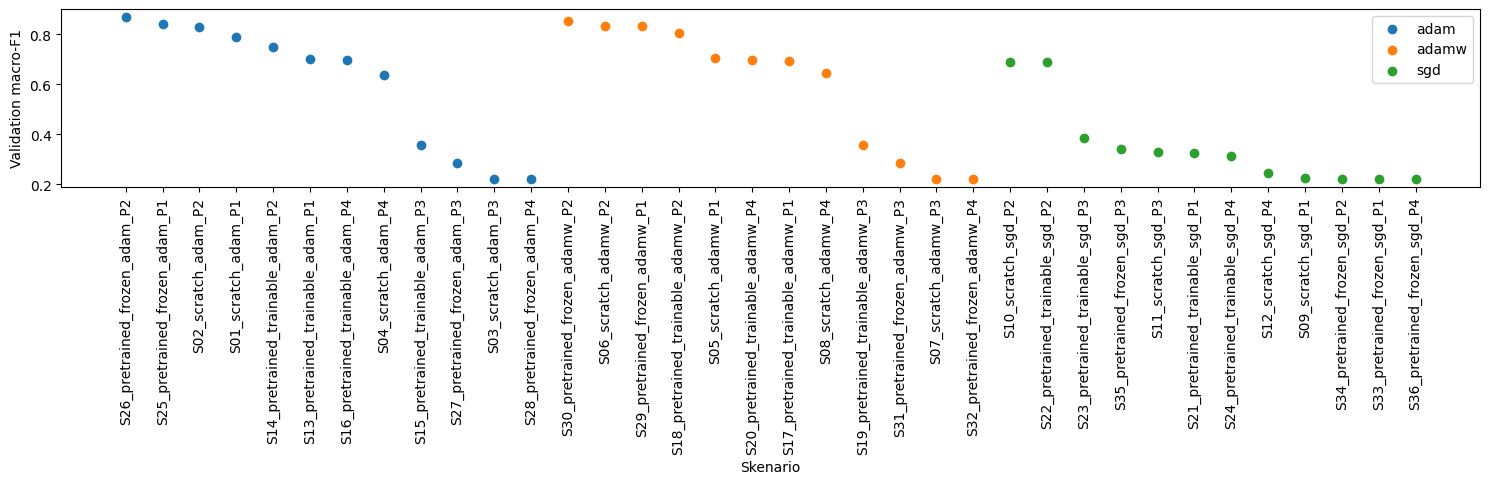

In [13]:
# ---------------------------------------------------------------------------
# 13. Perbandingan macro-F1 validasi
# ---------------------------------------------------------------------------
completed = leaderboard[leaderboard.status.eq("completed")].copy()
if len(completed):
    fig, ax = plt.subplots(figsize=(15, 5))
    for optimizer_name, group in completed.groupby("optimizer"):
        ax.scatter(group.scenario_id, group.val_f1, label=optimizer_name)
    ax.set(xlabel="Skenario", ylabel="Validation macro-F1")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "scenario_f1_comparison.png", dpi=160)
    plt.show()
    completed.groupby(["regime", "optimizer"]).val_f1.agg(["max", "mean", "count"]).to_csv(
        RUN_DIR / "group_summary.csv"
    )


In [14]:
# ---------------------------------------------------------------------------
# 14. Pemenang berdasarkan validation macro-F1
# ---------------------------------------------------------------------------
selection = json.loads((RUN_DIR / "best_model.json").read_text(encoding="utf-8"))
if "winner" in selection:
    winner = selection["winner"]
    print(f"Skenario terbaik: {winner['scenario_id']}")
    print(f"Epoch: {winner['best_epoch']} | validation macro-F1: {winner['val_f1']:.4f}")
    print(f"Validation loss: {winner['val_loss']:.4f} | AUROC: {winner['val_auroc']:.4f}")
    print(f"Diagnosis AUROC: {winner['val_diagnosis_auroc']:.4f}")
    print(f"Conditional severity AUROC: {winner['val_severity_auroc']:.4f}")
    print(f"Checkpoint: {winner['checkpoint_path']}")
    # Macro-F1 sama: val_loss lebih rendah, lalu scenario_id; dalam trial epoch lebih awal.
    print(f"Status pemilihan final: {selection['selection_final']}")
    # Macro AUROC tiga kelas tidak identik dengan AUROC diagnosis biner pada paper.
else:
    print("Belum ada trial yang berhasil. Periksa status/error.log pada masing-masing folder.")


Skenario terbaik: S26_pretrained_frozen_adam_P2
Epoch: 25 | validation macro-F1: 0.8685
Validation loss: 0.6146 | AUROC: 0.9231
Diagnosis AUROC: 0.9426
Conditional severity AUROC: 0.9406
Checkpoint: D:\Kuliah\Magister\Semester 1\Topik Dalam Pengolahan Citra Digital\Multimodal MIL-Attention based Hierarchical Classification Regensburg Pediatric Dataset\experiments\Experiment 1\runs\search_20261018_044822_847109_seed1\trials\S26_pretrained_frozen_adam_P2\best_model.pt
Status pemilihan final: True


In [16]:
# ---------------------------------------------------------------------------
# 15. Testing lengkap untuk checkpoint pemenang validation macro-F1
# ---------------------------------------------------------------------------
EVALUATE_TEST = True  # Setelah search selesai, True lalu jalankan cell ini saja.

if EVALUATE_TEST:
    # Semua evaluasi memakai pasien, checkpoint, dan threshold yang sama.
    # Image-only: embedding klinis dinolkan sebelum fusion.
    # Clinical-only: kedua embedding bag citra dinolkan sebelum fusion.
    # Ini intervensi inferensi, bukan baseline unimodal yang dilatih terpisah.
    # Tiap kondisi dilaporkan untuk all / single_image / multiple_images.
    # Severity q pada true appendicitis dipisahkan dari severity setelah gating.
    # Akurasi dalam kelas = recall; akurasi OvR juga menghitung true negatives.
    test_ds = make_dataset("test", X_test, y_test, test_imp, eval_tf)
    test_metrics, test_predictions = evaluate_search_winner(RUN_DIR, test_ds, SEARCH_SETTINGS)
    print_test_report(test_metrics["comprehensive_report_directory"])
else:
    print("Testing belum dijalankan; pemenang dipilih hanya dari validation macro-F1.")



Metrik dalam skala 0-1. Unit evaluasi: pasien.
Image-only/clinical-only adalah intervensi embedding, bukan baseline yang dilatih terpisah.
Accuracy within class = recall; accuracy OvR menghitung TN juga. NaN/null = tidak terdefinisi.

overview.csv
                      mode           group  patients  accuracy     f1  macro_f1  precision  sensitivity  specificity  balanced_accuracy  weighted_f1     mcc  cohen_kappa  auroc_macro_ovr  auprc_macro_average_precision  nll_three_classes  brier_three_classes  ece_top_label_argmax_10bins  argmax_accuracy                       accuracy_wilson_95ci  diagnosis_auroc  severity_direct_auroc  complicated_recall
                multimodal             all       116    0.7931 0.7925    0.7925     0.7808       0.8155       0.8915             0.8155       0.7915  0.6774       0.6709           0.9041                         0.8309             0.6432               0.3373                       0.0933           0.7931   [0.7105774078005253, 0.856838915975548